In [1]:
# ============================================================
# PHENOSENSING - EXPLORATION 1
# Analyse phénologique spatialement implicite
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import phenosensing
import pandas as pd

from phenosensing import load_sample



# ------------------------------------------------------------
# 1. Import dataset
# ------------------------------------------------------------

pheno_RI = pd.read_csv("../data/NDVI_modis_RI_2016_2026.csv")


In [2]:
# ------------------------------------------------------------
# 2. Préparer la série temporelle
# ------------------------------------------------------------

pheno_RI["date"] = pd.to_datetime(pheno_RI["date"])

pheno_RI = pheno_RI.sort_values("date")

# Ajouter année et jour de l'année
pheno_RI["year"] = pheno_RI["date"].dt.year
pheno_RI["doy"] = pheno_RI["date"].dt.dayofyear

# Garder uniquement 2016–2025
pheno_RI = pheno_RI[
    pheno_RI["date"].dt.year <= 2025
].copy()

In [3]:
# ------------------------------------------------------------
# 3. Créer un xarray.DataArray
# ------------------------------------------------------------

ts = xr.DataArray(
    pheno_RI["mean_ndvi"].values,
    coords={
        "time": pheno_RI["date"].values,
        "year": ("time", pheno_RI["year"].values),
        "doy": ("time", pheno_RI["doy"].values),
    },
    dims=["time"],
    name="NDVI"
)

In [57]:
# ============================================================
# 5. PHÉNOLOGIE ANNÉE PAR ANNÉE
# ============================================================

phenology_curves = {}
lsp_results = {}


for year in sorted(pheno_RI["year"].unique()):

    print(f"\n================ {year} ================")

    # --------------------------------------------------------
    # Extraire une année
    # --------------------------------------------------------

    ts_year = ts.where(
        ts.year == year,
        drop=True
    )

    print(
        f"Nombre d'observations : {ts_year.time.size}"
    )

    # --------------------------------------------------------
    # Reconstruction
    # --------------------------------------------------------

    shape = ts_year.pheno.PhenoShape(
        interpolType="whittaker",
        rollWindow=10,
        nGS=100
    )

    phenology_curves[year] = shape

    # --------------------------------------------------------
    # Extraction LSP
    # --------------------------------------------------------

    lsp = shape.pheno.PhenoLSP(
        extraction="der",
    )

    lsp_results[year] = lsp

    print(lsp)


================ 2016 ================
Nombre d'observations : 154
<xarray.Dataset> Size: 144B
Dimensions:  ()
Data variables: (12/18)
    sos      float64 8B 105.0
    pos      float64 8B 174.0
    eos      float64 8B 311.0
    vsos     float64 8B 0.7073
    vpos     float64 8B 0.8725
    veos     float64 8B 0.7905
    ...       ...
    ios      float64 8B 167.2
    rog      float64 8B 0.002394
    ros      float64 8B -0.0005984
    sw       float64 8B -1.861
    trough   float64 8B 0.5817
    mos      float64 8B 208.0

================ 2017 ================
Nombre d'observations : 178
<xarray.Dataset> Size: 144B
Dimensions:  ()
Data variables: (12/18)
    sos      float64 8B 99.0
    pos      float64 8B 194.0
    eos      float64 8B 310.0
    vsos     float64 8B 0.7334
    vpos     float64 8B 0.8725
    veos     float64 8B 0.7306
    ...       ...
    ios      float64 8B 171.3
    rog      float64 8B 0.001464
    ros      float64 8B -0.001223
    sw       float64 8B -1.018
    troug

In [5]:
type(lsp_results)
type(phenology_curves)

dict

## plot des phenos annuelles

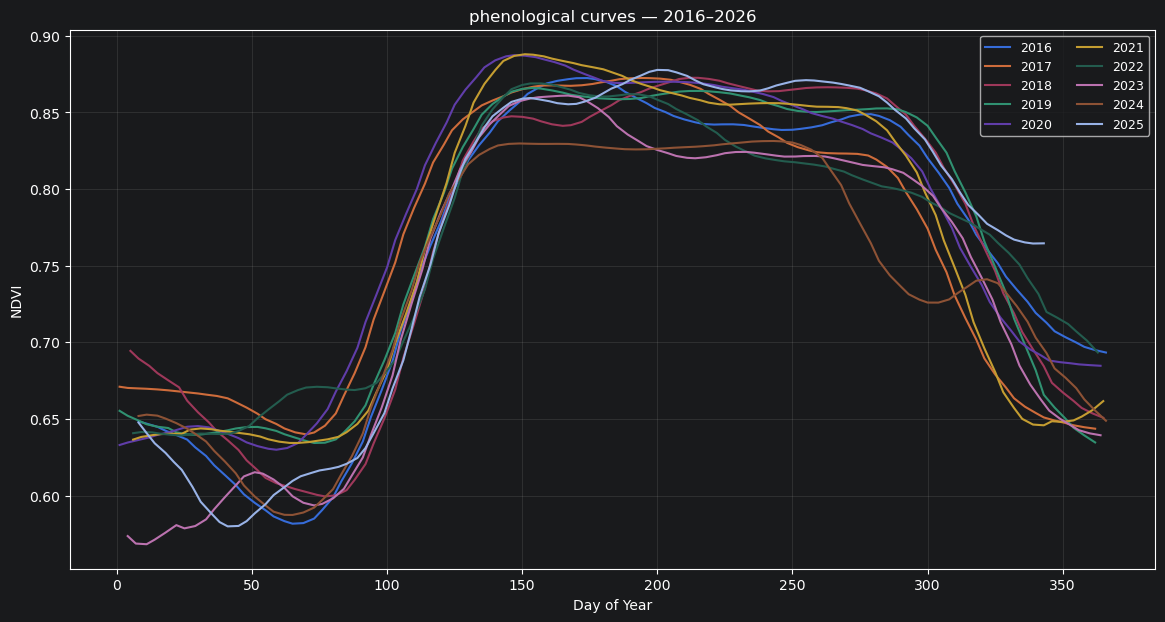

In [58]:
plt.figure(figsize=(14, 7))

for year, curve in phenology_curves.items():

    plt.plot(
        curve.doy,
        curve,
        label=str(year)
    )

plt.xlabel("Day of Year")
plt.ylabel("NDVI")
plt.title("phenological curves — 2016–2026")

plt.legend(
    ncol=2,
    fontsize=9
)

plt.grid(alpha=0.2)

plt.show()

# variations des metriques ?

In [63]:
# ============================================================
# 7. Extraire SOS / POS / EOS / LOS
# ============================================================

results = []

for year, lsp in lsp_results.items():

    row = {
        "year": year
    }

    for metric in [
        "sos",
        "pos",
        "eos",
        "los",
        "ampl"
    ]:

        if metric in lsp:
            row[metric] = float(lsp[metric].values)

    results.append(row)


phenology_df = pd.DataFrame(results)

print("\nRésultats :")
print(phenology_df)


Résultats :
   year    sos    pos    eos    los      ampl
0  2016  105.0  174.0  311.0  206.0  0.290778
1  2017   99.0  194.0  310.0  211.0  0.232518
2  2018  114.0  212.0  321.0  207.0  0.273146
3  2019  110.0  154.0  332.0  222.0  0.231697
4  2020   96.0  147.0  309.0  213.0  0.257440
5  2021  114.0  151.0  314.0  200.0  0.253640
6  2022  117.0  157.0  341.0  224.0  0.229736
7  2023  105.0  167.0  327.0  222.0  0.292721
8  2024  102.0  243.0  275.0  173.0  0.244000
9  2025  112.0  200.0  305.0  193.0  0.297832


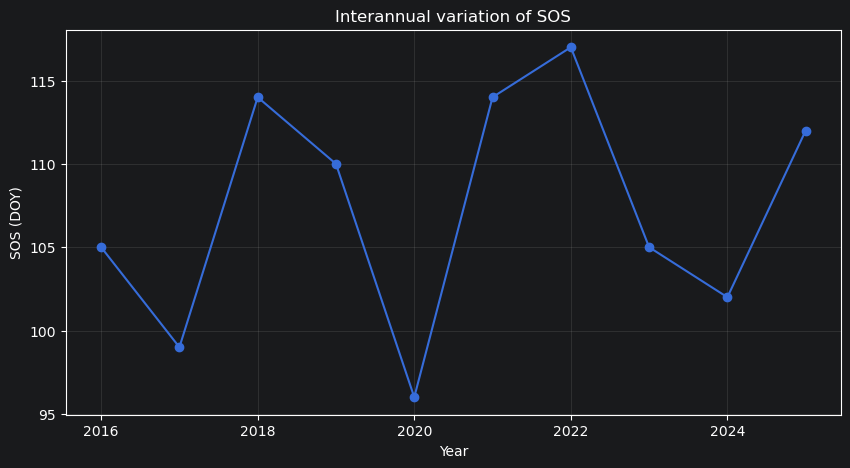

In [60]:
plt.figure(figsize=(10, 5))

plt.plot(
    phenology_df["year"],
    phenology_df["sos"],
    marker="o"
)

plt.xlabel("Year")
plt.ylabel("SOS (DOY)")
plt.title("Interannual variation of SOS")

plt.grid(alpha=0.2)

plt.show()

lien avec années de floraisons ?

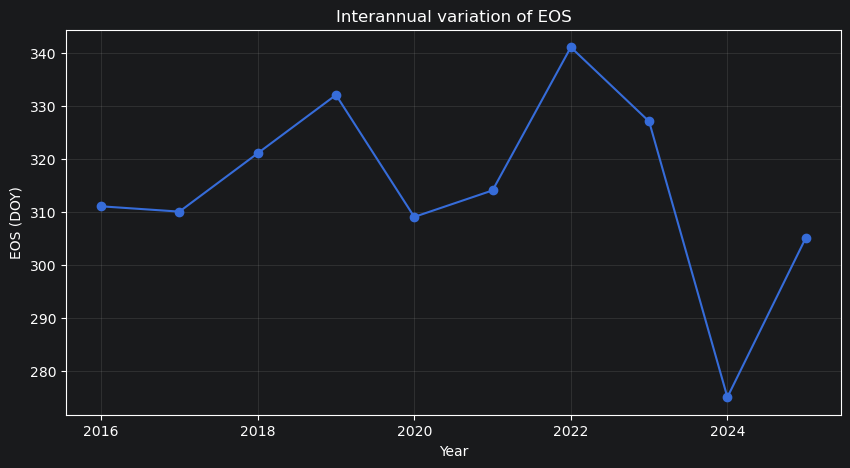

In [61]:
plt.figure(figsize=(10, 5))

plt.plot(
    phenology_df["year"],
    phenology_df["eos"],
    marker="o"
)

plt.xlabel("Year")
plt.ylabel("EOS (DOY)")
plt.title("Interannual variation of EOS")

plt.grid(alpha=0.2)

plt.show()

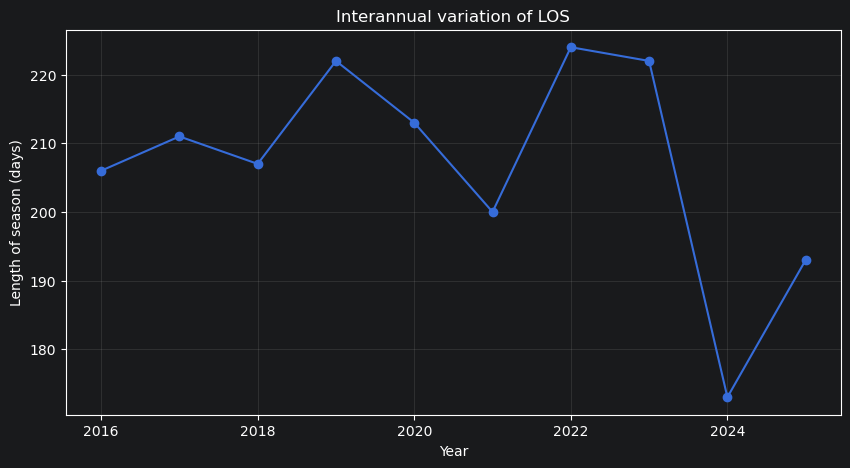

In [62]:
plt.figure(figsize=(10, 5))

plt.plot(
    phenology_df["year"],
    phenology_df["los"],
    marker="o"
)

plt.xlabel("Year")
plt.ylabel("Length of season (days)")
plt.title("Interannual variation of LOS")

plt.grid(alpha=0.2)

plt.show()